# AAVAIL revenue forecasting - Exploratory data analysis

**Business question:** can AAVAIL predict the revenue of the next 30 days, for the top 10 countries and for all countries combined, at any point in time?

This notebook explores the training data (`data/cs-train`) after ingestion with `ingestion.py`:
1. the raw invoices and data quality issues
2. revenue over time and seasonality
3. which countries drive revenue
4. how revenue relates to the other features (purchases, invoices, streams, views)

Charts are also saved to `images/`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ingestion import DATA_DIR, fetch_data, fetch_ts, country_key

plt.style.use("seaborn-v0_8-whitegrid")
plt.rc("figure", figsize=(12, 4.5))
os.makedirs("images", exist_ok=True)

## 1. Raw invoices and data quality

In [2]:
df = fetch_data(DATA_DIR)
print("invoice lines: {:,}".format(len(df)))
print("date range:    {} to {} ({} days)".format(df.invoice_date.min().date(), df.invoice_date.max().date(),
                                               (df.invoice_date.max() - df.invoice_date.min()).days + 1))
print("countries:     {}".format(df.country.nunique()))
print("customers:     {:,}  (missing customer_id: {:,})".format(df.customer_id.nunique(), df.customer_id.isnull().sum()))
print("zero-price lines: {:,}".format((df.price == 0).sum()))
df.head()

invoice lines: 815,008
date range:    2017-11-28 to 2019-07-31 (611 days)
countries:     43


customers:     5,225  (missing customer_id: 189,759)
zero-price lines: 5,365


,country,customer_id,day,invoice,month,price,stream_id,times_viewed,year,invoice_date
0,United Kingdom,13085.0,28,489434,11,6.95,85048,12,2017,2017-11-28
1,United Kingdom,13085.0,28,489434,11,6.75,79323W,12,2017,2017-11-28
2,United Kingdom,13085.0,28,489434,11,2.10,22041,21,2017,2017-11-28
3,United Kingdom,13085.0,28,489434,11,1.25,21232,5,2017,2017-11-28
4,United Kingdom,13085.0,28,489434,11,1.65,22064,17,2017,2017-11-28


**Data quality notes**
- The JSON files use two naming schemes (`StreamID`/`stream_id`, `TimesViewed`/`times_viewed`, `total_price`/`price`); `ingestion.py` harmonizes them.
- Invoice ids sometimes include letters (e.g. a `C` prefix); only the numeric part is kept.
- 3 lines with negative prices (accounting adjustments, e.g. -53,594) are removed.
- `customer_id` is missing for many lines; it is not needed because the target is aggregated revenue.

## 2. Revenue over time

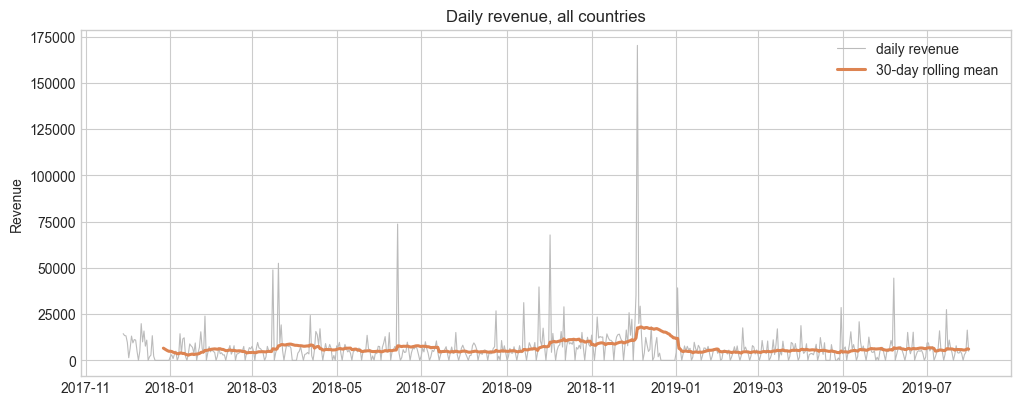

In [3]:
ts = fetch_ts(DATA_DIR)
all_ts = ts["all"].set_index("date")

fig, ax = plt.subplots()
ax.plot(all_ts.index, all_ts.revenue, color="#BBBBBB", lw=0.8, label="daily revenue")
ax.plot(all_ts.index, all_ts.revenue.rolling(30).mean(), color="#DD8452", lw=2.2, label="30-day rolling mean")
ax.set_title("Daily revenue, all countries")
ax.set_ylabel("Revenue")
ax.legend()
fig.savefig("images/revenue_over_time.png", dpi=110, bbox_inches="tight")
plt.show()

Revenue is fairly stable through most of the year, but there is a strong peak from **September to December 2018** (holiday season) and a dip in February. With fewer than two years of data, only one full seasonal cycle is observed, so the model cannot learn yearly seasonality reliably.

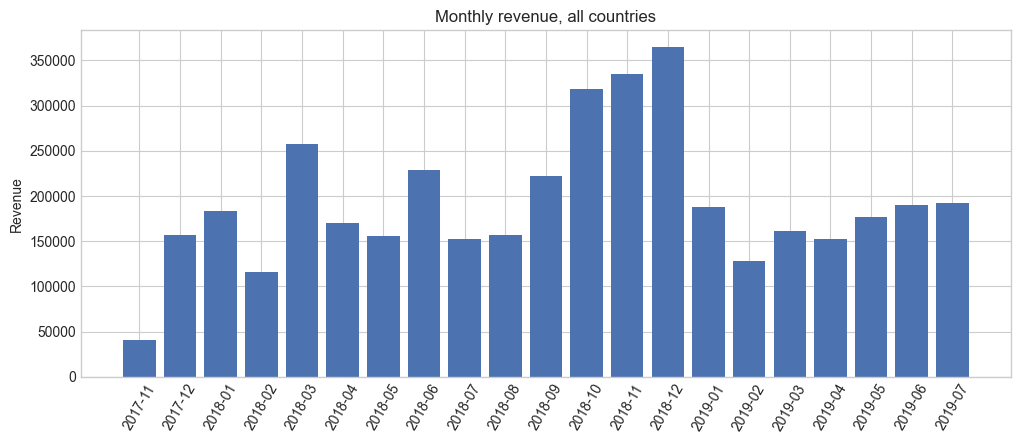

,revenue,purchases,total_views
year_month,,,
2017-11,41153.0,9502,44972
2017-12,157155.0,35726,165047
2018-01,183680.0,35682,176494
2018-02,116345.0,29873,157529
2018-03,257428.0,38618,201318
2018-04,170237.0,33182,182944
2018-05,155749.0,38391,205171
2018-06,229099.0,38987,205126
2018-07,152411.0,34096,185210


In [4]:
monthly = ts["all"].groupby("year_month")[["revenue", "purchases", "total_views"]].sum()
fig, ax = plt.subplots()
ax.bar(monthly.index, monthly.revenue, color="#4C72B0")
ax.set_title("Monthly revenue, all countries")
ax.set_ylabel("Revenue")
ax.tick_params(axis="x", rotation=60)
fig.savefig("images/monthly_revenue.png", dpi=110, bbox_inches="tight")
plt.show()
monthly.round(0)

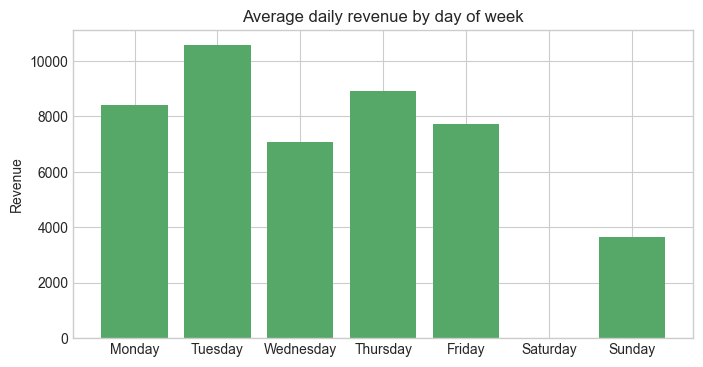

In [5]:
dow = all_ts.groupby(all_ts.index.day_name())["revenue"].mean()
dow = dow.reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(dow.index, dow.values, color="#55A868")
ax.set_title("Average daily revenue by day of week")
ax.set_ylabel("Revenue")
plt.show()

Saturdays have almost no revenue, so daily values are noisy; forecasting the **30-day total** smooths out the weekly pattern.

## 3. Which countries drive revenue

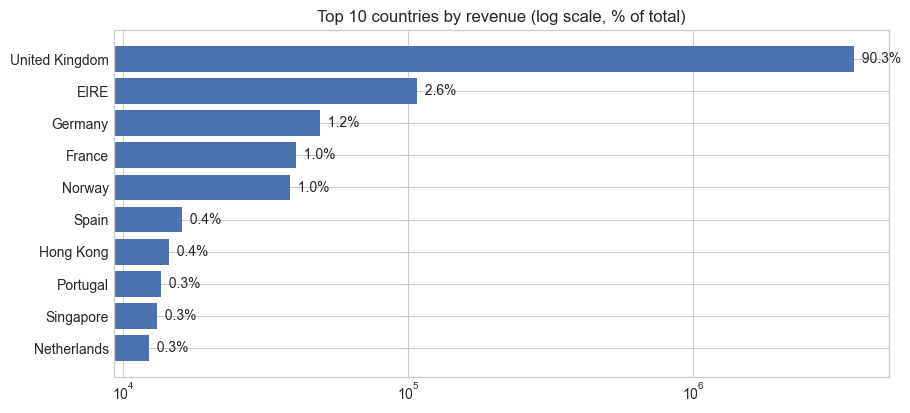

top 10 share of revenue: 97.8%


In [6]:
by_country = df.groupby("country")["price"].sum().sort_values(ascending=False)
top = by_country.head(10)
share = top / by_country.sum() * 100

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(top.index[::-1], top.values[::-1], color="#4C72B0")
for i, (c, v) in enumerate(top[::-1].items()):
    ax.text(v, i, "  {:.1f}%".format(share[c]), va="center")
ax.set_xscale("log")
ax.set_title("Top 10 countries by revenue (log scale, % of total)")
fig.savefig("images/top_countries.png", dpi=110, bbox_inches="tight")
plt.show()
print("top 10 share of revenue: {:.1f}%".format(share.sum()))

The **United Kingdom accounts for about 90%** of revenue, so the 'all countries' series is driven almost entirely by the UK. The other top-10 countries have small, noisy series with many zero days, which makes them harder to forecast.

## 4. Revenue and the other features

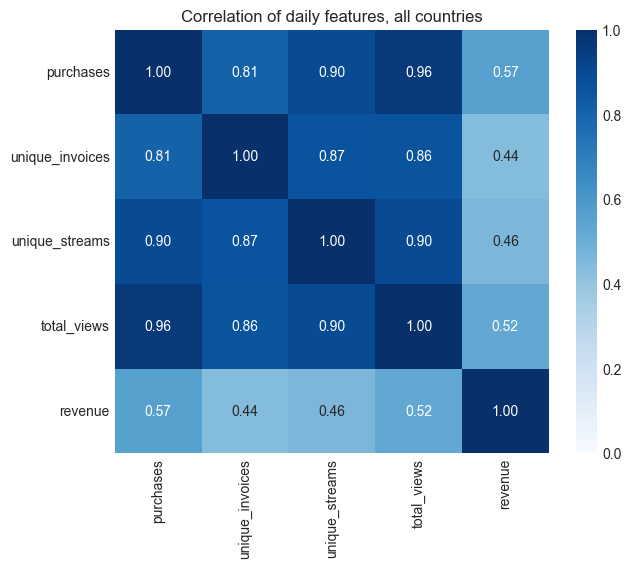

In [7]:
feats = ts["all"][["purchases", "unique_invoices", "unique_streams", "total_views", "revenue"]]
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(feats.corr(), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax)
ax.set_title("Correlation of daily features, all countries")
fig.savefig("images/feature_correlation.png", dpi=110, bbox_inches="tight")
plt.show()

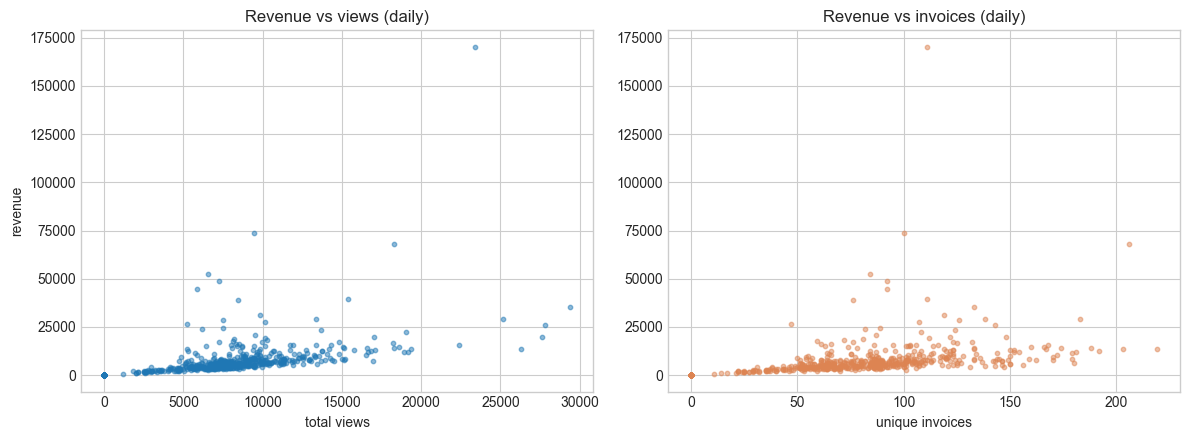

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(feats.total_views, feats.revenue, s=10, alpha=0.5)
axes[0].set_xlabel("total views"); axes[0].set_ylabel("revenue"); axes[0].set_title("Revenue vs views (daily)")
axes[1].scatter(feats.unique_invoices, feats.revenue, s=10, alpha=0.5, color="#DD8452")
axes[1].set_xlabel("unique invoices"); axes[1].set_title("Revenue vs invoices (daily)")
plt.tight_layout()
plt.show()

Revenue is strongly correlated with purchases, invoices, streams and views, so recent activity is a useful predictor of upcoming revenue.

## Summary and next steps
- ~21 months of data (Nov 2017 - Jul 2019), 815k invoice lines, 43 countries; the UK dominates revenue.
- Clear holiday peak in Q4 and weekly pattern (no Saturday revenue).
- Features for the model: revenue over the previous 7/14/28/70 days plus recent invoices and views; target = revenue over the next 30 days.
- Hypotheses to test: a model on these features beats a 'last 28 days' baseline, and the best model type differs by country (see `model.py compare`).